Форма координат: (2000, 3)
Радиусы: 14.999999999999996 15.000000000000004
Минимальное расстояние между центрами: 1.0370810202877014
Создание геометрии и дерева, с: 0.000992499990388751


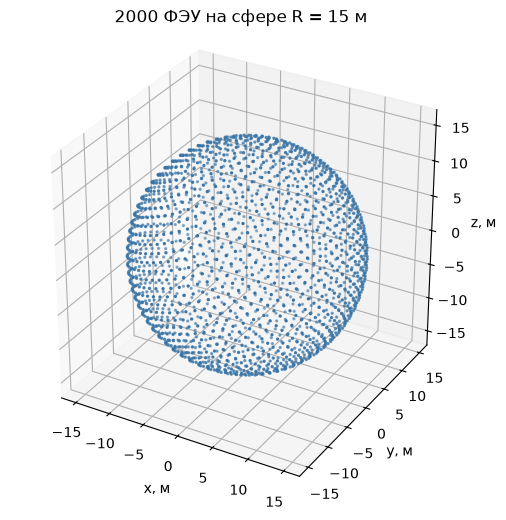

In [1]:
%matplotlib inline

import sys
import importlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import detector_model_v4 as dm
dm = importlib.reload(dm)
import time
import csv

t0 = time.perf_counter()
large = dm.Detector(R=15.0, N=2000, r=0.10, a=0.5)
build_time = time.perf_counter() - t0
print("Форма координат:", large.pmt_positions.shape)
print("Радиусы:", np.linalg.norm(large.pmt_positions, axis=1).min(),
      np.linalg.norm(large.pmt_positions, axis=1).max())
nearest_distances, _ = large.tree.query(large.pmt_positions, k=2)
print("Минимальное расстояние между центрами:", nearest_distances[:, 1].min())
print("Создание геометрии и дерева, с:", build_time)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
x, y, z = large.pmt_positions.T
ax.scatter(x, y, z, s=2, color="#3773a5")
ax.set(xlabel="x, м", ylabel="y, м", zlabel="z, м", title="2000 ФЭУ на сфере R = 15 м")
ax.set_box_aspect((1, 1, 1))
Path("results_v4").mkdir(exist_ok=True)
fig.savefig("results_v4/hw08_geometry.png", dpi=160)
plt.show()

In [2]:
rng = np.random.default_rng(808)
M = 5000
points = large.R * dm.random_directions(M, rng)
points = np.vstack((points, large.pmt_positions[:20]))
ids_full = large.find_pmt(points, method="full")
ids_tree = large.find_pmt(points, method="tree")
print("Совпали:", np.array_equal(ids_full, ids_tree))
print("Число попаданий:", np.count_nonzero(ids_tree >= 0))
assert np.array_equal(ids_full, ids_tree)

Совпали: True
Число попаданий: 136


**Измерим ускорение поиска на 2000 ФЭУ**

In [3]:
def measure(function, repeats=3):
    function()
    values = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        function()
        values.append(time.perf_counter() - t0)
    return float(np.median(values))

t_full = measure(lambda: large.find_pmt(points, method="full"))
t_tree = measure(lambda: large.find_pmt(points, method="tree"))
print(f"NumPy, полный поиск: {t_full:.6f} с")
print(f"KDTree:              {t_tree:.6f} с")
print(f"Отношение:           {t_full/t_tree:.2f}")

# Для медленного двойного цикла берём одинаковое подмножество.
subset = points[:1000]
assert np.array_equal(large.find_pmt_loop(subset), large.find_pmt(subset, "tree"))
t_python = measure(lambda: large.find_pmt_loop(subset))
t_tree_subset = measure(lambda: large.find_pmt(subset, "tree"))
print(f"Python, 1000 точек:   {t_python:.6f} с")
print(f"KDTree, 1000 точек:   {t_tree_subset:.6f} с")
print(f"Ускорение к Python:   {t_python/t_tree_subset:.2f}")

out = Path("results_v4")
out.mkdir(exist_ok=True)
with (out / "hw08_search_timings.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["method", "photons", "seconds"])
    writer.writerows([["full_numpy", len(points), t_full], ["KDTree", len(points), t_tree],
                     ["python_loop", len(subset), t_python],
                     ["KDTree_subset", len(subset), t_tree_subset],
                     ["geometry_and_tree_build", 0, build_time]])

NumPy, полный поиск: 0.044553 с
KDTree:              0.002884 с
Отношение:           15.45
Python, 1000 точек:   2.922295 с
KDTree, 1000 точек:   0.000601 с
Ускорение к Python:   4864.82


In [4]:
large_z = np.array([-10.0, 0.0, 10.0])
large_results = {}
for i, z in enumerate(large_z):
    source_z = dm.Source(Y=10_000, position=(0.0, 0.0, z))
    large_results[float(z)] = dm.response_pair(
        large, source_z, E=1.0, n_events=500, seed=8200 + i,
        attenuation_length=8.0, batch_size=1000, method="tree"
    )
    pair = large_results[float(z)]
    print(f"z={z:+.1f}: без затухания={pair[:,0].mean():.3f}, "
          f"с затуханием={pair[:,1].mean():.3f}")

center = large_results[0.0]
expected0 = dm.central_expectation(large)
expected8 = dm.central_expectation(large, attenuation_length=8.0)
print("Теория из центра:", expected0, expected8)
print("Теоретическое отношение:", np.exp(-15.0/8.0))

z=-10.0: без затухания=111.310, с затуханием=29.108
z=+0.0: без затухания=111.944, с затуханием=17.056
z=+10.0: без затухания=111.520, с затуханием=29.394
Теория из центра: 111.11111111111113 17.03944076054761
Теоретическое отношение: 0.15335496684492847


В центре аналитические средние - **111.111 фотоэлектрона без затухания** и **17.0394 с затуханием**, отношение около **0.153355**. Увеличение числа ФЭУ с 40 до 2000 не увеличивает средний сигнал в 50 раз: площадь сферы тоже растёт. Доля покрытия равна примерно 2.22%, а длинный путь 15 м заметно подавляет свет.